## TUGAS PREPROCESSING DATASET HOUSE PRICES

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

dataset_path = '5054251040_Muhammad_Nazwar_Fakhrurrozy_Tugas_Praproses_Data.csv'
df = pd.read_csv(dataset_path)

print(f"Dimensi Dataset: {df.shape[0]} baris, {df.shape[1]} kolom\n")
df.head()

Dimensi Dataset: 1460 baris, 81 kolom



,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Data Cleaning

In [27]:
# 1. Hitung persentase missing values per kolom
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Jumlah Missing': df.isnull().sum(),
    'Persentase (%)': missing_pct
}).query('`Jumlah Missing` > 0').sort_values(by='Persentase (%)', ascending=False)

print("--- Ringkasan Kolom dengan Missing Values ---")
print(missing_df)

cols_to_drop = missing_pct[missing_pct > 50].index.tolist()
print(f"\nKolom yang dihapus (> 50% missing): {cols_to_drop}")

df_clean = df.drop(columns=cols_to_drop)
print(f"Dimensi dataset setelah menghapus kolom > 50% missing: {df_clean.shape}")

--- Ringkasan Kolom dengan Missing Values ---
              Jumlah Missing  Persentase (%)
PoolQC                  1453       99.520548
MiscFeature             1406       96.301370
Alley                   1369       93.767123
Fence                   1179       80.753425
MasVnrType               872       59.726027
FireplaceQu              690       47.260274
LotFrontage              259       17.739726
GarageType                81        5.547945
GarageYrBlt               81        5.547945
GarageFinish              81        5.547945
GarageQual                81        5.547945
GarageCond                81        5.547945
BsmtExposure              38        2.602740
BsmtFinType2              38        2.602740
BsmtQual                  37        2.534247
BsmtCond                  37        2.534247
BsmtFinType1              37        2.534247
MasVnrArea                 8        0.547945
Electrical                 1        0.068493

Kolom yang dihapus (> 50% missing): ['Alley', 'MasVnr

ini output buat ngedeteksi missing values. kolom yang nilai kosongnya di atas 50 persen langsung dibuang karena datanya terlalu bolong, sisanya baru dipertahanin buat diisi pakai metode imputasi

In [28]:
none_cols = [
    'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 
    'BsmtExposure', 'BsmtFinType2', 'BsmtQual', 'BsmtCond', 'BsmtFinType1'
]
for col in none_cols:
    df_clean[col] = df_clean[col].fillna('None')

df_clean['LotFrontage'] = df_clean.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

df_clean['GarageYrBlt'] = df_clean['GarageYrBlt'].fillna(0)

df_clean['MasVnrArea'] = df_clean['MasVnrArea'].fillna(0)

df_clean['Electrical'] = df_clean['Electrical'].fillna(df_clean['Electrical'].mode()[0])
print(f"Jumlah Sisa Missing Values Keseluruhan: {df_clean.isnull().sum().sum()}")

Jumlah Sisa Missing Values Keseluruhan: 0


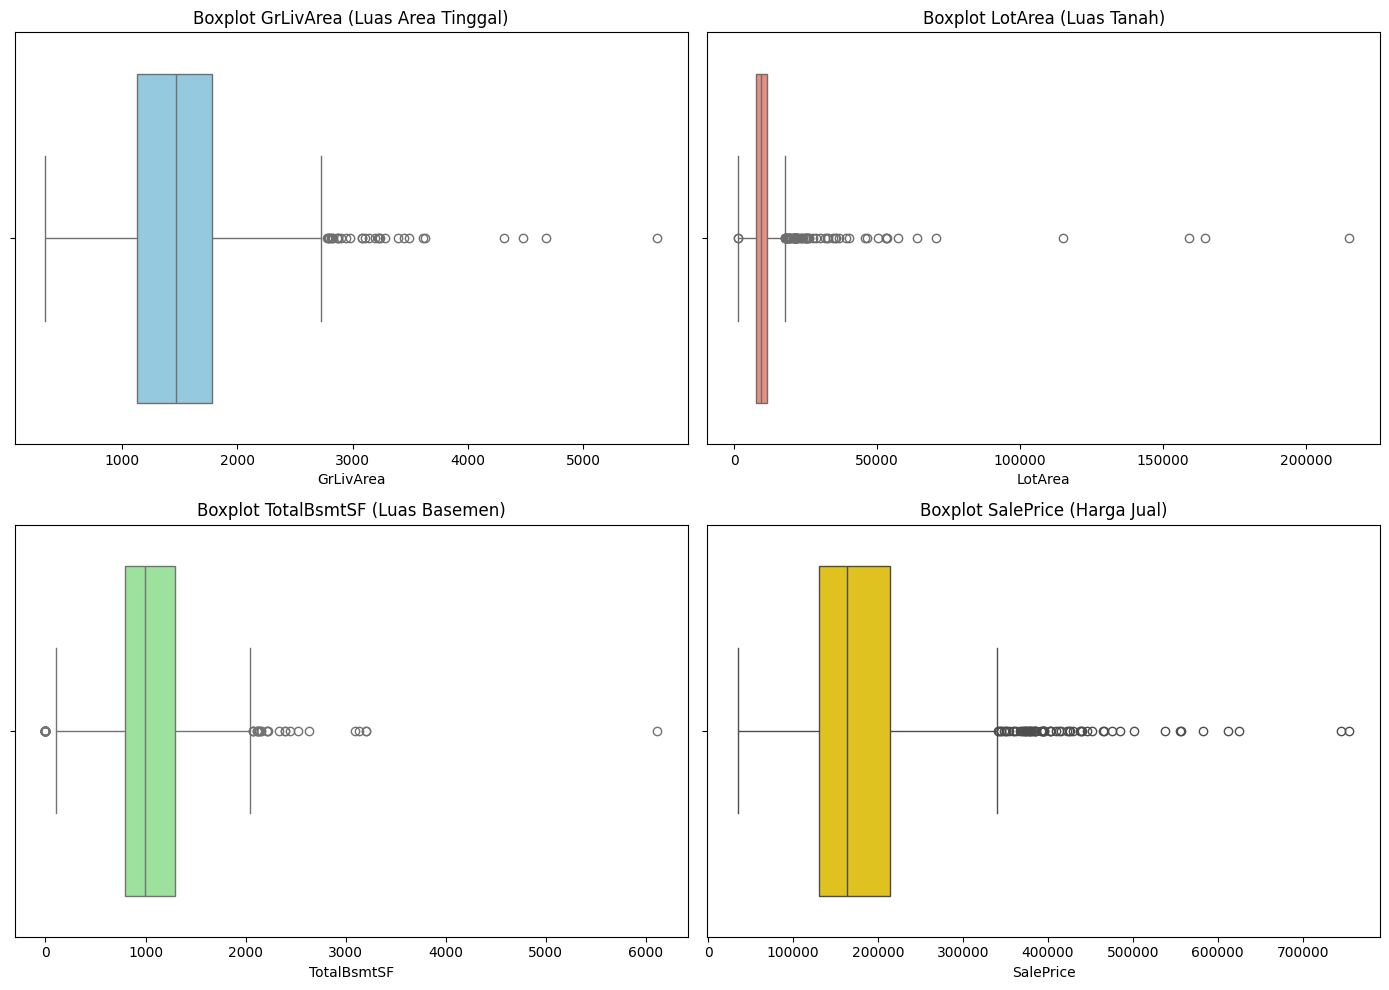

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(ax=axes[0, 0], x=df_clean['GrLivArea'], color='skyblue')
axes[0, 0].set_title('Boxplot GrLivArea (Luas Area Tinggal)')

sns.boxplot(ax=axes[0, 1], x=df_clean['LotArea'], color='salmon')
axes[0, 1].set_title('Boxplot LotArea (Luas Tanah)')

sns.boxplot(ax=axes[1, 0], x=df_clean['TotalBsmtSF'], color='lightgreen')
axes[1, 0].set_title('Boxplot TotalBsmtSF (Luas Basemen)')

sns.boxplot(ax=axes[1, 1], x=df_clean['SalePrice'], color='gold')
axes[1, 1].set_title('Boxplot SalePrice (Harga Jual)')

plt.tight_layout()
plt.show()

ini visualisasi boxplot buat ngecek outlier di fitur utama. kelihatan banget semuanya menceng ke kanan dan banyak titik outlier ekstrem, makanya perlu dibatasi pakai IQR capping biar nilainya ga terlalu liar

In [30]:
num_cols_outliers = ['GrLivArea', 'LotArea', 'TotalBsmtSF', 'LotFrontage']

for col in num_cols_outliers:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df_clean[col] = np.where(df_clean[col] > upper_bound, upper_bound,
                             np.where(df_clean[col] < lower_bound, lower_bound, df_clean[col]))

print("Penanganan outlier dengan IQR Capping selesai dilakukan pada fitur numerik utama.")

Penanganan outlier dengan IQR Capping selesai dilakukan pada fitur numerik utama.


nilai ekstrem yang di luar batas atas dan bawah dipangkas ke nilai batas terdekat, jadi baris datanya ga perlu dibuang dan jumlah data tetap utuh

## Transformasi Data

In [31]:
cat_cols = df_clean.select_dtypes(include=['object', 'str']).columns.tolist()
num_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()

if 'Id' in num_cols:
    num_cols.remove('Id')
if 'SalePrice' in num_cols:
    num_cols.remove('SalePrice')

df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)
print(f"Dimensi setelah One-Hot Encoding: {df_encoded.shape}")

scaler = StandardScaler()
df_transformed = df_encoded.copy()
df_transformed[num_cols] = scaler.fit_transform(df_encoded[num_cols])

print("Standarisasi (StandardScaler) berhasil diterapkan pada fitur numerik.")
df_transformed.head()

Dimensi setelah One-Hot Encoding: (1460, 245)
Standarisasi (StandardScaler) berhasil diterapkan pada fitur numerik.


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,1,0.073375,-0.249286,-0.333244,0.651479,-0.517200,1.050994,0.878668,0.514104,0.575425,...,False,False,False,False,True,False,False,False,True,False
1,2,-0.872563,0.583251,-0.013189,-0.071836,2.179628,0.156734,-0.429577,-0.570750,1.171992,...,False,False,False,False,True,False,False,False,True,False
2,3,0.073375,-0.082779,0.446022,0.651479,-0.517200,0.984752,0.830215,0.325915,0.092907,...,False,False,False,False,True,False,False,False,True,False
3,4,0.309859,-0.526798,-0.027104,0.651479,-0.517200,-1.863632,-0.720298,-0.570750,-0.499274,...,False,False,False,False,True,False,False,False,False,False
4,5,0.073375,0.805261,1.283733,1.374795,-0.517200,0.951632,0.733308,1.366489,0.463568,...,False,False,False,False,True,False,False,False,True,False


## Reduksi Dimensi

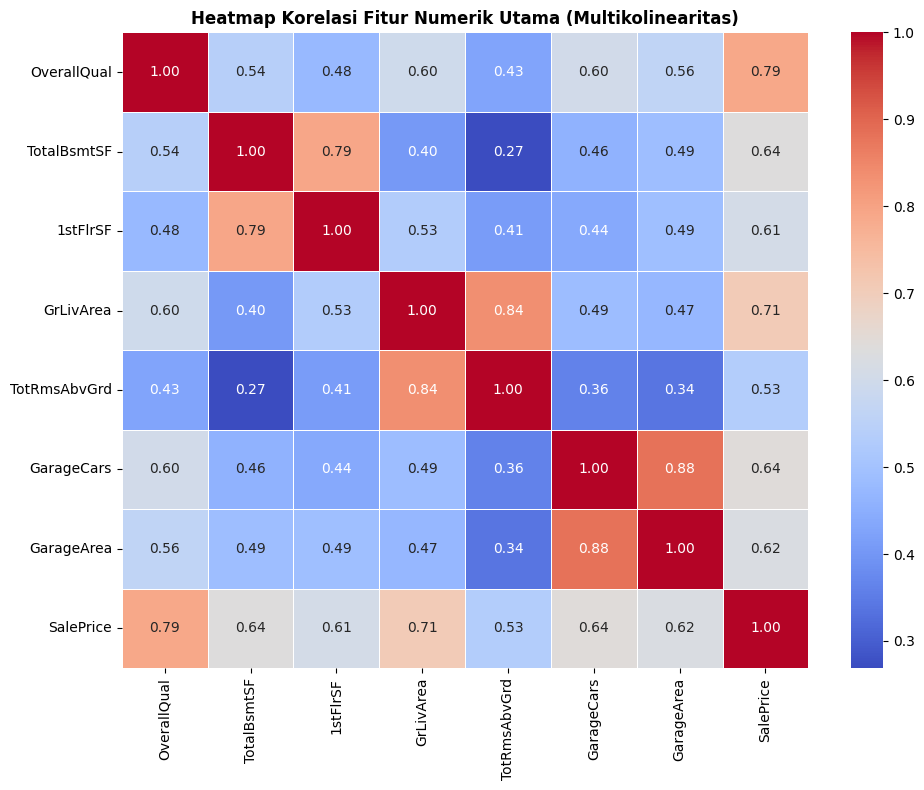

In [32]:
top_corr = df_clean.select_dtypes(include=[np.number]).drop(columns=['Id']).corr()
high_corr_features = top_corr.columns[(top_corr.abs() > 0.70).sum() > 1]

plt.figure(figsize=(10, 8))
sns.heatmap(
    df_clean[high_corr_features].corr(), 
    annot=True, 
    cmap='coolwarm', 
    fmt='.2f', 
    linewidths=0.5
)
plt.title('Heatmap Korelasi Fitur Numerik Utama (Multikolinearitas)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

da beberapa pasang fitur yang angkanya mendekati 1 seperti GarageCars sama GarageArea atau GrLivArea sama TotRmsAbvGrd. karena mereka ngasih informasi yang hampir sama persis, salah satunya wajib dibuang biar gak terjadi multikolinearitas

In [33]:
corr_matrix = df_transformed.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.85) and column != 'SalePrice']

print(f"Jumlah fitur yang dibuang karena korelasi sangat tinggi (> 0.85): {len(to_drop)}")
print(f"Fitur yang dibuang: {to_drop[:10]} ...")

df_reduced = df_transformed.drop(columns=to_drop)
print(f"Dimensi dataset setelah eliminasi korelasi tinggi: {df_reduced.shape}")

Jumlah fitur yang dibuang karena korelasi sangat tinggi (> 0.85): 21
Fitur yang dibuang: ['GarageArea', 'Neighborhood_Somerst', 'RoofStyle_Hip', 'Exterior2nd_CBlock', 'Exterior2nd_CmentBd', 'Exterior2nd_HdBoard', 'Exterior2nd_MetalSd', 'Exterior2nd_VinylSd', 'Exterior2nd_Wd Sdng', 'ExterQual_TA'] ...
Dimensi dataset setelah eliminasi korelasi tinggi: (1460, 224)


In [34]:
X = df_reduced.drop(columns=['Id', 'SalePrice'])
y = df_reduced['SalePrice']

pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X)

print(f"Jumlah fitur sebelum PCA: {X.shape[1]}")
print(f"Jumlah komponen utama (PCA) yang mempertahankan 90% varians: {pca.n_components_}")

pca_cols = [f'PC{i+1}' for i in range(pca.n_components_)]
df_pca = pd.DataFrame(X_pca, columns=pca_cols)
df_final = pd.concat([df_reduced[['Id']].reset_index(drop=True), df_pca, y.reset_index(drop=True)], axis=1)

print(f"\nDimensi Dataset Akhir Siap Pakai: {df_final.shape}")

output_filename = '5054251040_Muhammad_Nazwar_Fakhrurrozy_Tugas_Praproses_Data.csv'
df_final.to_csv(output_filename, index=False)
print(f"Dataset hasil praproses berhasil disimpan ke: {output_filename}")

Jumlah fitur sebelum PCA: 222
Jumlah komponen utama (PCA) yang mempertahankan 90% varians: 43

Dimensi Dataset Akhir Siap Pakai: (1460, 45)
Dataset hasil praproses berhasil disimpan ke: 5054251040_Muhammad_Nazwar_Fakhrurrozy_Tugas_Praproses_Data.csv


di tahap transformasi data, fitur teks diubah jadi angka biner pakai one hot encoding dan semua fitur numerik disamakan skalanya pakai standardscaler. fungsinya biar model bisa baca data teks dan gak ada variabel bernilai besar seperti luas tanah yang mendominasi variabel bernilai kecil seperti jumlah kamar. dan lanjut di reduksi data, fitur yang korelasinya terlalu mirip dibuang lalu sisanya diringkas pakai pca dari ratusan kolom jadi 43 komponen utama saja. fungsinya buat ngilangin informasi ganda yang bikin model bingung dan bikin proses komputasi jauh lebih cepat tanpa kehilangan 90 persen informasi pentingnya